# Sustainable portfolio selection with QAOA, Part 2: constraint-preserving mixer and preference trade-offs

We continue with the fund problem from Part 1 (`01_penalty_formulation.ipynb`): choose exactly 3 of 6 funds, with $\lambda = 0.15$. Here we extend the method and then examine the policy question:

1. **Classical baselines**, against which the quantum results are compared (Section 1).
2. **A mixer that never breaks the rule**: the XY mixer started from a Dicke state, so no penalty is needed (Section 2).
3. **A training protocol**: several random starts with median and spread, the probability of the optimum as the main metric, and layerwise initialization (Section 3).
4. **A head-to-head comparison** with the penalty method of Part 1 (Section 4).
5. **Scaling up** to 8 funds and 70 valid portfolios (Section 5).
6. **The sustainability weight $\eta$**: how it changes the chosen portfolio, and who gains or loses (Section 6).
7. **Reflection** on who defines the objective and what is left out (Section 7).

`python portfolio_qaoa.py --part 2` prints the main results in a terminal.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from qiskit.quantum_info import Statevector
import portfolio_qaoa as pq

print("Qiskit", qiskit.__version__)
pf = pq.example_portfolio()
ex = pq.brute_force(pf)
DEPTHS = [1, 2, 3, 4, 5]
print(f"Exact optimum (brute force): {ex.best}, f* = {ex.f_star:.3f}")

Qiskit 2.5.1
Exact optimum (brute force): ABC, f* = -6.975


## 1. Classical baselines

We first establish simple classical baselines:
- **Brute force** over the 20 valid portfolios: exact, and instant at this size.
- **Random valid portfolio:** each guess is the optimum with probability $1/20 = 0.05$.
- **Greedy + swap:** add the fund that lowers $f$ most until 3 are held. Then swap one held fund for an unheld one, for as long as that improves $f$.

In [2]:
x, fx, calls = pq.greedy_swap(pf)
print(f"greedy + swap: {pq.assets(pf, x)}, f = {fx:.3f}, using {calls} evaluations of f (brute force uses 20)\n")
for N in [1, 10, 100, 4096]:
    print(f"N = {N:4d} random valid guesses: P(ABC appears at least once) = {1 - (19 / 20) ** N:.4f}")

greedy + swap: ABC, f = -6.975, using 25 evaluations of f (brute force uses 20)

N =    1 random valid guesses: P(ABC appears at least once) = 0.0500
N =   10 random valid guesses: P(ABC appears at least once) = 0.4013
N =  100 random valid guesses: P(ABC appears at least once) = 0.9941
N = 4096 random valid guesses: P(ABC appears at least once) = 1.0000


Greedy finds the optimum, using 25 evaluations of $f$, more than brute force's 20 at this size. At this size classical methods are clearly sufficient. The aim of the quantum study is a verified, constraint-preserving formulation whose circuit grows polynomially with the number of funds, not a speedup on 6 funds. The last lines show that the optimum appearing somewhere in 4096 shots is not evidence of performance, since random guessing achieves the same.

## 2. A mixer that never breaks the rule

We start in a state that already holds exactly 3 funds, and use a mixer that can only *swap* a held fund for an unheld one.

**Start: the Dicke state**, an equal superposition of all 20 valid portfolios:

$$|D^6_3\rangle = \frac{1}{\sqrt{20}}\sum_{x:\ \sum_i x_i = 3} |x\rangle .$$

**Mixer: XY swaps** on neighbouring qubits $(i, j)$ of the ring $0-1-2-3-4-5-0$:

$$U_{ij}(\beta) = e^{-i\beta(X_iX_j + Y_iY_j)/2} = R_{XX}(\beta)\,R_{YY}(\beta).$$

Why it keeps the count: $\tfrac12(X_iX_j + Y_iY_j)$ maps $|01\rangle \leftrightarrow |10\rangle$ and sends $|00\rangle$ and $|11\rangle$ to zero. It moves a "1" between qubits but never creates or destroys one; equivalently, it commutes with $\sum_i Z_i$. Every state the circuit can reach holds exactly 3 funds, so the cost Hamiltonian needs **no penalty** ($A = 0$): only $f$ itself is encoded.

The cell below checks that no probability leaks out of the valid portfolios for random angles. It also compares circuit sizes after compiling to CX gates.

In [3]:
H0, offset0 = pq.cost_hamiltonian(pf, penalty=0.0)
print("diag(H) + C equals f(x) for all 64 bitstrings:", np.allclose(pq.diagonal(H0) + offset0, ex.f))

rng = np.random.default_rng(3)
q3 = pq.QAOA(H0, p=3, mixer="xy", k=pf.k)
leak = max(q3.probabilities(rng.uniform(-np.pi, np.pi, 6))[~ex.feasible].sum() for _ in range(10))
print(f"largest probability outside the 20 valid portfolios (10 random angle sets): {leak:.1e}")
print(f"Dicke start: P(ABC) = {Statevector(q3.initial).probabilities()[ex.optimal].sum():.3f} (= 1/20)\n")

H2, _ = pq.cost_hamiltonian(pf, penalty=2.0)
print(pq.table([{"p": p, **{f"X mixer {key}": val for key, val in pq.gate_counts(pq.QAOA(H2, p, "x")).items()},
                 **{f"XY mixer {key}": val for key, val in pq.gate_counts(pq.QAOA(H0, p, "xy", k=pf.k)).items()}}
                for p in [1, 3, 5]]))

diag(H) + C equals f(x) for all 64 bitstrings: True
largest probability outside the 20 valid portfolios (10 random angle sets): 1.0e-29
Dicke start: P(ABC) = 0.050 (= 1/20)



p  X mixer CX gates  X mixer depth  XY mixer CX gates  XY mixer depth
-  ----------------  -------------  -----------------  --------------
1                30             35                109             354
3                90             81                213             526
5               150            127                317             698


At depth 5 the XY circuit needs about twice as many CX gates as the X circuit (317 against 150). Each XY swap costs CX gates, while the X mixer uses only single-qubit rotations. Preparing the Dicke state with Qiskit's generic `StatePreparation` adds a fixed overhead; a dedicated circuit (Bärtschi and Eidenbenz, 2019) needs only $O(nK)$ gates. The guarantee also holds only without noise: on a real device a bit flip can still leave the valid set, so invalid shots would still be discarded.

## 3. Training protocol

**Multiple random starts.** The energy landscape has many valleys, and where COBYLA ends depends on where it starts. A single run is one random draw, so we run 5 random starts per depth and report the median and the interquartile range (IQR, the middle half of the runs). The best run shows what is possible; the median shows what to expect.

**Probability of the optimum.** We report $P_\text{opt}$ as the main metric. With $N$ shots, the optimum "appears in the samples" with probability $1 - (1 - P_\text{opt})^N$. That is almost 1 for any reasonable $N$, even for random guessing (Section 1). $P_\text{opt}$, together with the quality of the average valid portfolio, shows how much the circuit actually concentrates on the answer.

**Layerwise initialization (INTERP).** Good QAOA angles form a smooth schedule, much like a slow "annealing" ramp: $\gamma_k$ tends to grow and $|\beta_k|$ to shrink with the layer index $k$. INTERP (Zhou et al., 2020) stretches the best depth-$p$ schedule onto $p+1$ layers by linear interpolation:

$$\theta^{(p+1)}_i = \frac{i-1}{p}\,\theta^{(p)}_{i-1} + \frac{p-i+1}{p}\,\theta^{(p)}_i,\qquad i = 1, \dots, p+1,\qquad \theta^{(p)}_0 = \theta^{(p)}_{p+1} = 0.$$

This is applied separately to the $\gamma$'s and the $\beta$'s. For example, $p = 1 \to 2$ copies the single angle into both layers, and $p = 2 \to 3$ gives $\big(\theta_1,\ \tfrac12(\theta_1 + \theta_2),\ \theta_2\big)$. The optimizer then starts there with a small step size. Each depth thus requires one optimization started near a good minimum, rather than a fresh random guess.

In [4]:
xy_runs = pq.depth_scan(ex, H0, DEPTHS, mixer="xy", n_random=5, seed=0)
summary = pq.summary_by_depth(xy_runs, "P_opt")
print(pq.table(summary))

p  random median P_opt          IQR  random best  layerwise / ramp
-  -------------------  -----------  -----------  ----------------
1                0.025  0.025-0.076        0.077             0.036
2                0.125  0.107-0.193        0.274             0.192
3                0.195  0.147-0.334        0.394             0.363
4                0.226  0.121-0.367        0.398             0.725
5                0.349  0.329-0.521        0.574             0.842


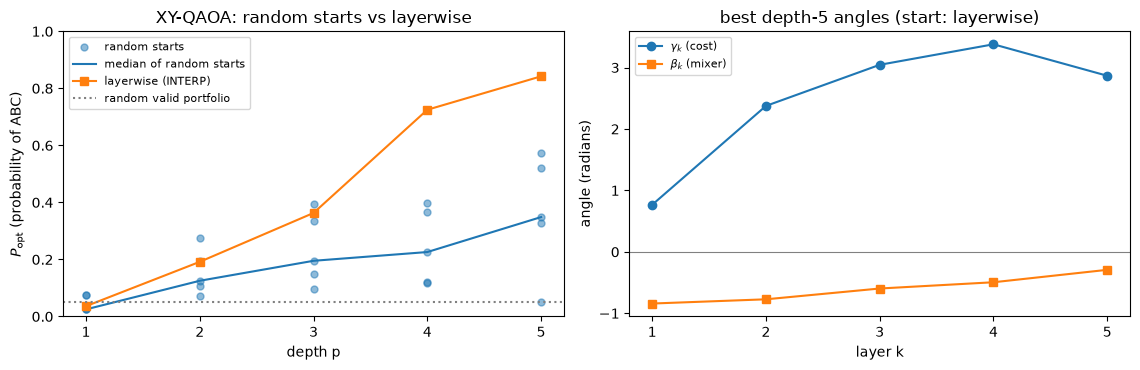

gamma: [0.767 2.376 3.045 3.379 2.866] | beta: [-0.841 -0.772 -0.597 -0.495 -0.293]


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
ax = axes[0]
for p in DEPTHS:
    vals = [r.P_opt for r in xy_runs if r.p == p and r.start.startswith("random")]
    ax.scatter([p] * len(vals), vals, color="tab:blue", alpha=0.5, s=25, label="random starts" if p == 1 else None)
ax.plot(DEPTHS, [row["random median P_opt"] for row in summary], color="tab:blue", label="median of random starts")
ax.plot(DEPTHS, [row["layerwise / ramp"] for row in summary], "s-", color="tab:orange", label="layerwise (INTERP)")
ax.axhline(1 / 20, color="gray", ls=":", label="random valid portfolio")
ax.set(xlabel="depth p", ylabel=r"$P_\mathrm{opt}$ (probability of ABC)", title="XY-QAOA: random starts vs layerwise",
       xticks=DEPTHS, ylim=(0, 1))
ax.legend(fontsize=8)

best5 = pq.best_by_energy(xy_runs)[5]
ax = axes[1]
layers = np.arange(1, 6)
ax.plot(layers, best5.theta[:5], "o-", label=r"$\gamma_k$ (cost)")
ax.plot(layers, best5.theta[5:], "s-", label=r"$\beta_k$ (mixer)")
ax.axhline(0, color="gray", lw=0.8)
ax.set(xlabel="layer k", ylabel="angle (radians)", title=f"best depth-5 angles (start: {best5.start})", xticks=layers)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print("gamma:", np.round(best5.theta[:5], 3), "| beta:", np.round(best5.theta[5:], 3))

With layerwise starts, $P_\text{opt}$ reaches 0.73 at $p = 4$ and 0.84 at $p = 5$. The medians of the random starts are 0.23 and 0.35, and a random valid guess gives 0.05. The right panel shows the best depth-5 schedule: $|\beta_k|$ shrinks steadily from 0.84 to 0.29, while $\gamma_k$ rises from 0.77 to about 3. INTERP relies on this smooth, annealing-like structure.

## 4. Comparison with the penalty method

Both methods get the same depths, the same 5 random starts plus a layerwise start, and the same cap of 400 optimizer evaluations per run. We compare the lowest-energy run at each depth. The penalty method from Part 1 uses the X mixer with $A = 2$.

p  X+penalty P_feas  X+penalty P_opt  X+penalty quality  XY P_feas  XY P_opt  XY quality
-  ----------------  ---------------  -----------------  ---------  --------  ----------
1             0.578            0.032              0.596      1.000     0.076       0.714
2             0.575            0.036              0.616      1.000     0.274       0.834
3             0.563            0.061              0.696      1.000     0.334       0.898
4             0.675            0.123              0.777      1.000     0.725       0.934
5             0.493            0.305              0.951      1.000     0.842       0.942


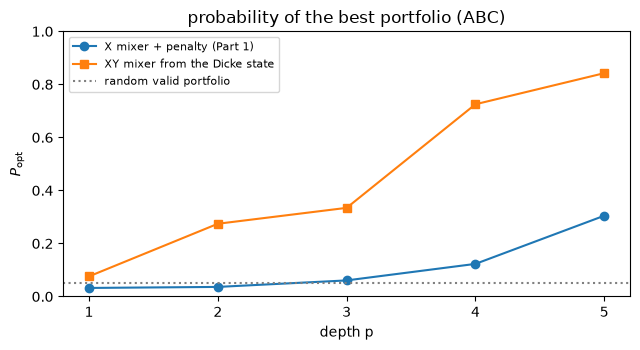

4096 shots of the depth-5 XY circuit:
Qiskit key  assets  count  valid       f  optimal
----------  ------  -----  -----  ------  -------
    000111     ABC   3445   True  -6.975     True
    011001     ADE     94   True  -5.942    False
    010101     ACE     80   True  -6.242    False
    010011     ABE     68   True  -6.533    False
    100011     ABF     67   True  -6.242    False
    001011     ABD     60   True  -6.808    False


In [6]:
x_runs = pq.depth_scan(ex, H2, DEPTHS, mixer="x", penalty=2.0, n_random=5, seed=0)
bx, bxy = pq.best_by_energy(x_runs), pq.best_by_energy(xy_runs)
print(pq.table([{"p": p, "X+penalty P_feas": bx[p].P_feas, "X+penalty P_opt": bx[p].P_opt, "X+penalty quality": bx[p].quality,
                 "XY P_feas": bxy[p].P_feas, "XY P_opt": bxy[p].P_opt, "XY quality": bxy[p].quality} for p in DEPTHS]))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(DEPTHS, [bx[p].P_opt for p in DEPTHS], "o-", label="X mixer + penalty (Part 1)")
ax.plot(DEPTHS, [bxy[p].P_opt for p in DEPTHS], "s-", label="XY mixer from the Dicke state")
ax.axhline(1 / 20, color="gray", ls=":", label="random valid portfolio")
ax.set(xlabel="depth p", ylabel=r"$P_\mathrm{opt}$", title="probability of the best portfolio (ABC)", xticks=DEPTHS, ylim=(0, 1))
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

counts = pq.QAOA(H0, 5, "xy", k=pf.k).sample(bxy[5].theta, shots=4096, seed=7)
print("4096 shots of the depth-5 XY circuit:")
print(pq.table(pq.decode_counts(counts, ex, top=6)))

The XY mixer gives higher validity and higher $P_\text{opt}$ at every depth. All of its samples are valid, and at $p = 5$ the best portfolio appears in 84% of shots (3445 of 4096). The penalty method reaches 31%, and half of its shots are invalid portfolios. The price is a deeper circuit (Section 2).

## 5. Scaling up: 8 funds, choose 4

We add two funds, G (return 7.5, ESG 4) and H (return 5.5, ESG 8.5), which mix both risk factors. That gives 8 qubits, 256 bitstrings and $\binom{8}{4} = 70$ valid portfolios, so a random valid guess finds the optimum with probability $1/70 \approx 0.014$. The pipeline is the same: XY mixer from the Dicke state, with 3 random starts plus a layerwise start per depth.

256 bitstrings, 70 valid portfolios. Best valid:
assets  return   risk    ESG       f
------  ------  -----  -----  ------
  ABCG   7.875  6.160  3.000  -6.951
  ABDG   7.625  5.504  3.750  -6.799
  ABCD   7.500  5.531  4.000  -6.670
  ABGH   7.500  5.660  3.875  -6.651

greedy + swap: ABCG after 43 evaluations | A_crit = 1.16, answer-free safe penalty A > 5.46
diag(H) + C equals f(x) for all 256 bitstrings: True


p  random median P_opt          IQR  random best  layerwise / ramp
-  -------------------  -----------  -----------  ----------------
1                0.049  0.042-0.049        0.049             0.035
2                0.072  0.065-0.075        0.078             0.116
3                0.056  0.054-0.064        0.072             0.217
4                0.091  0.074-0.132        0.172             0.478
5                0.140  0.114-0.266        0.392             0.591


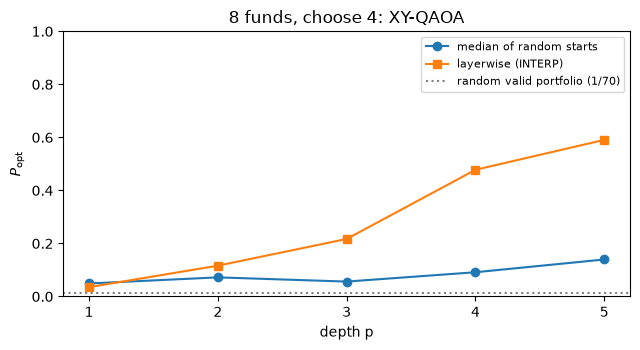

In [7]:
pf8 = pq.example_portfolio(n=8)
ex8 = pq.brute_force(pf8)
print(f"{len(ex8.f)} bitstrings, {ex8.feasible.sum()} valid portfolios. Best valid:")
print(pq.table(ex8.ranking(top=4)))
x8, f8, calls8 = pq.greedy_swap(pf8)
print(f"\ngreedy + swap: {pq.assets(pf8, x8)} after {calls8} evaluations | A_crit = {pq.critical_penalty(ex8):.2f}, "
      f"answer-free safe penalty A > {pq.safe_penalty(pf8)['A_safe']:.2f}")

H8, offset8 = pq.cost_hamiltonian(pf8, penalty=0.0)
print("diag(H) + C equals f(x) for all 256 bitstrings:", np.allclose(pq.diagonal(H8) + offset8, ex8.f))
runs8 = pq.depth_scan(ex8, H8, DEPTHS, mixer="xy", n_random=3, seed=0)
summary8 = pq.summary_by_depth(runs8, "P_opt")
print(pq.table(summary8))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(DEPTHS, [row["random median P_opt"] for row in summary8], "o-", label="median of random starts")
ax.plot(DEPTHS, [row["layerwise / ramp"] for row in summary8], "s-", label="layerwise (INTERP)")
ax.axhline(1 / 70, color="gray", ls=":", label="random valid portfolio (1/70)")
ax.set(xlabel="depth p", ylabel=r"$P_\mathrm{opt}$", title="8 funds, choose 4: XY-QAOA", xticks=DEPTHS, ylim=(0, 1))
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

The optimum ABCG holds the three highest-return carbon-intensive funds plus G. Layerwise XY-QAOA reaches $P_\text{opt} = 0.59$ at $p = 5$, about 40 times a random valid guess (0.014), while the median random start reaches 0.14. Concentration is lower than with 6 funds (0.84) at the same depth: the search space is 3.5 times larger, and the runner-up ABDG is again close (0.152 worse). Larger instances are therefore likely to require deeper circuits.

## 6. Changing the sustainability weight $\eta$

So far $\eta = 0$, so sustainability was ignored. Raising $\eta$ rewards higher ESG scores. This changes the *question*, not the algorithm. Costs at different $\eta$ are not comparable, so we compare the chosen portfolios' return, risk and ESG score instead.

from eta  assets  return  risk   ESG
--------  ------  ------  ----  ----
    0.00     ABC    8.00  6.83  2.67
    0.17     ABD    7.67  5.72  3.67
    0.28     ACD    7.33  5.33  4.67
    0.45     ADE    6.67  4.83  6.00
    0.53     CDE    6.00  5.06  7.33
    0.77     DEF    5.00  6.83  9.00


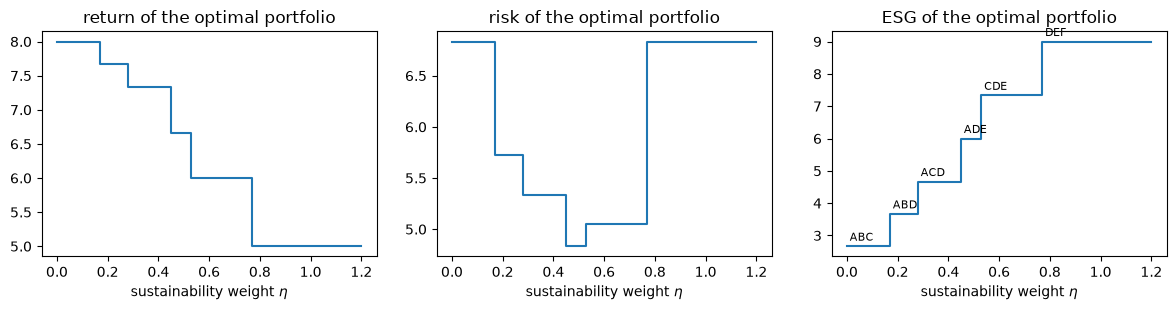

In [8]:
etas = np.round(np.arange(0, 1.2001, 0.01), 2)
path = [pq.brute_force(pf.with_(eta=e)).ranking(top=1)[0] for e in etas]
switches = [{"from eta": e, **row} for i, (e, row) in enumerate(zip(etas, path))
            if i == 0 or row["assets"] != path[i - 1]["assets"]]
print(pq.table(switches, ["from eta", "assets", "return", "risk", "ESG"], digits=2))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharex=True)
for ax, key in zip(axes, ["return", "risk", "ESG"]):
    ax.step(etas, [row[key] for row in path], where="post")
    ax.set(xlabel=r"sustainability weight $\eta$", title=f"{key} of the optimal portfolio")
for row in switches:
    axes[2].annotate(row["assets"], (row["from eta"], row["ESG"]), textcoords="offset points", xytext=(2, 4), fontsize=8)
plt.tight_layout()
plt.show()

Six different "optimal" portfolios appear as $\eta$ goes from 0 to 0.77. Each step trades return for sustainability, from ABC (return 8.0, ESG 2.7) to DEF (return 5.0, ESG 9.0). Risk does not move in one direction: it is lowest at ADE, which mixes both groups of funds, and rises again as the portfolio shifts into D–F, whose funds all move together.

Next we check that XY-QAOA finds the right portfolio at five weights. To keep the run short, it uses 2 random starts plus the layerwise start per depth, up to $p = 5$.

In [9]:
rows = []
for eta in [0.0, 0.25, 0.5, 0.75, 1.0]:
    pf_eta = pf.with_(eta=eta)
    ex_eta = pq.brute_force(pf_eta)
    first, second = ex_eta.ranking(top=2)
    H_eta, _ = pq.cost_hamiltonian(pf_eta, penalty=0.0)
    run = pq.best_by_energy(pq.depth_scan(ex_eta, H_eta, DEPTHS, mixer="xy", n_random=2, seed=1))[5]
    rows.append({"eta": eta, "exact optimum": first["assets"], "runner-up": second["assets"],
                 "gap in f": second["f"] - first["f"],
                 "QAOA most likely": pq.assets(pf_eta, ex_eta.X[np.argmax(run.probs)]), "P_opt": run.P_opt})
print(pq.table(rows))

  eta  exact optimum  runner-up  gap in f  QAOA most likely  P_opt
-----  -------------  ---------  --------  ----------------  -----
0.000            ABC        ABD     0.167               ABC  0.841
0.250            ABD        ACD     0.025               ABD  0.548
0.500            ADE        CDE     0.033               ADE  0.733
0.750            CDE        DEF     0.017               CDE  0.658
1.000            DEF        CDE     0.400               DEF  0.643


At every weight, the most likely portfolio from XY-QAOA is the brute-force optimum, with $P_\text{opt}$ between 0.55 and 0.84. Near-ties are common: at three of the five weights the runner-up is within 0.033 of the optimum. A small change in $\eta$ would change the answer there, so the decision is fragile whichever solver is used.

## 7. Reflection: who defines "optimal"?

- **Who chose the objective?** The trustees choose $\lambda$ and $\eta$, and a data vendor defines the ESG score. Section 6 shows that $\eta$ alone decides between six portfolios. The algorithm faithfully optimizes whatever is encoded; it cannot tell whether the weights reflect what members want.
- **Who gains and who loses?** Raising $\eta$ from 0 to 1 cuts the expected return from 8.0 to 5.0 (in this instance's units) and raises the ESG score from 2.7 to 9.0. Members close to retirement bear that cost most directly, while communities near carbon-intensive operations stand to gain. Neither group appears in the objective explicitly.
- **What is left out?** The ESG score compresses many issues into one number and can hide serious harms. A fund that crosses a red line (for example, human-rights abuses) should be excluded by a hard constraint, not traded against return. Equal weights, the fixed $K$, fees, liquidity and uncertainty in $\mu$ and $\Sigma$ are also left out.
- **How would we detect harm?** Report return, risk and ESG separately rather than only the combined $f$. Show the switch points in $\eta$. Flag near-ties, where the "optimal" portfolio is close to a coin flip between options that affect people differently.
- **When should a human decide?** When there are near-ties, when the weights are contested, or when an option crosses a red line. Here QAOA is a decision-support tool that lists good options and their trade-offs, not a decision maker.
- **Who gets access?** If quantum optimization ever beats classical methods on problems like this, large asset managers will have it first. For 6 funds, brute force on a laptop is exact and free.

**Limits of this study.**
- The data is invented.
- With 6 or 8 funds (64 or 256 bitstrings), classical brute force is instant.
- All simulations are noiseless.
- $P_\text{opt}$ uses the known optimum, which is impossible at large scale. There one would compare against the best known classical solution or a certified bound.

## References

1. E. Farhi, J. Goldstone, S. Gutmann, "A Quantum Approximate Optimization Algorithm", arXiv:1411.4028 (2014).
2. S. Hadfield et al., "From the Quantum Approximate Optimization Algorithm to a Quantum Alternating Operator Ansatz", *Algorithms* 12(2), 34 (2019). Mixers that preserve constraints, including XY mixers.
3. L. Zhou, S.-T. Wang, S. Choi, H. Pichler, M. D. Lukin, "Quantum Approximate Optimization Algorithm: Performance, Mechanism, and Implementation on Near-Term Devices", *Phys. Rev. X* 10, 021067 (2020). INTERP initialization.
4. A. Bärtschi, S. Eidenbenz, "Deterministic Preparation of Dicke States", arXiv:1904.07358 (2019).
5. M. Hodson, B. Ruck, H. Ong, D. Garvin, S. Dulman, "Portfolio rebalancing experiments using the Quantum Alternating Operator Ansatz", arXiv:1911.05296 (2019).
6. A. Lucas, "Ising formulations of many NP problems", *Front. Phys.* 2, 5 (2014). Penalty encodings.
7. H. Markowitz, "Portfolio Selection", *J. Finance* 7(1), 77–91 (1952).
8. G. Nannicini, "Quantum algorithms for optimizers", lecture notes, arXiv:2408.07086 (2024).
9. Qiskit Finance, [portfolio optimization tutorial](https://qiskit-community.github.io/qiskit-finance/tutorials/01_portfolio_optimization.html); Qiskit Optimization, [converters for quadratic programs](https://qiskit-community.github.io/qiskit-optimization/tutorials/02_converters_for_quadratic_programs.html).
10. B. Tirado, "Combinatorial Optimization with QAOA: Max-Cut", BasQ Qiskit Fall Fest 2026 (CC BY 4.0), the Track 2 starter notebook.